In [15]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    f1_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reprodutibilidade
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# Caminho dos dados
RAIZ = Path("../Dados")

def carregar(nome):
    return pd.read_csv(RAIZ / nome)


df_orders = carregar("./Brazilian Logistic/olist_orders_dataset.csv")
df_items = carregar("./Brazilian Logistic/olist_order_items_dataset.csv")
df_customers = carregar("./Brazilian Logistic/olist_customers_dataset.csv")
df_sellers = carregar("./Brazilian Logistic/olist_sellers_dataset.csv")
df_products = carregar("./Brazilian Logistic/olist_products_dataset.csv")
df_payments = carregar("./Brazilian Logistic/olist_order_payments_dataset.csv")
df_geo = carregar("./Brazilian Logistic/olist_geolocation_dataset.csv")
df_reviews = carregar("./Brazilian Logistic/olist_order_reviews_dataset.csv")

print("Dados carregados com sucesso!")


ModuleNotFoundError: No module named 'tensorflow'

In [70]:

# Conversão das datas
datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in datas:
    df_orders[coluna] = pd.to_datetime(df_orders[coluna], errors="coerce")

# Geolocalização: média das coordenadas por CEP
df_geo["geolocation_zip_code_prefix"] = (
    df_geo["geolocation_zip_code_prefix"].astype(str).str.zfill(5)
)

geo = df_geo.groupby("geolocation_zip_code_prefix", as_index=False).agg(
    latitude=("geolocation_lat", "mean"),
    longitude=("geolocation_lng", "mean")
)

# Coordenadas dos clientes
df_customers["customer_zip_code_prefix"] = (
    df_customers["customer_zip_code_prefix"].astype(str).str.zfill(5)
)

clientes = df_customers.merge(
    geo,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
).rename(columns={"latitude": "customer_lat", "longitude": "customer_lng"})

# Coordenadas dos vendedores
df_sellers["seller_zip_code_prefix"] = (
    df_sellers["seller_zip_code_prefix"].astype(str).str.zfill(5)
)

vendedores = df_sellers.merge(
    geo,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
).rename(columns={"latitude": "seller_lat", "longitude": "seller_lng"})

# Integração dos itens, produtos e vendedores
itens = df_items.merge(
    df_products, on="product_id", how="left"
).merge(
    vendedores[["seller_id", "seller_state", "seller_lat", "seller_lng"]],
    on="seller_id", how="left"
)

# Função para obter a categoria mais frequente
def moda(coluna):
    valores = coluna.mode()
    return valores.iloc[0] if not valores.empty else np.nan

# Agregação dos itens por pedido
itens_agg = itens.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    seller_count=("seller_id", "nunique"),
    product_count=("product_id", "nunique"),
    price_sum=("price", "sum"),
    freight_sum=("freight_value", "sum"),
    weight_sum=("product_weight_g", "sum"),
    volume_sum=("product_length_cm", lambda x: 0),  # substituído abaixo
    product_category=("product_category_name", moda),
    seller_state=("seller_state", moda),
    seller_lat=("seller_lat", "mean"),
    seller_lng=("seller_lng", "mean")
).reset_index()

# Volume total dos produtos por pedido
itens["product_volume"] = (
    itens["product_length_cm"] *
    itens["product_height_cm"] *
    itens["product_width_cm"]
)

volume = itens.groupby("order_id")["product_volume"].sum().rename("volume_sum")

itens_agg = itens_agg.drop(columns="volume_sum").merge(
    volume, on="order_id", how="left"
)

# Agregação dos pagamentos
pagamentos = df_payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", moda)
).reset_index()

# Integração geral
df = df_orders.merge(
    clientes[["customer_id", "customer_state", "customer_lat", "customer_lng"]],
    on="customer_id", how="left"
)

df = df.merge(itens_agg, on="order_id", how="left")
df = df.merge(pagamentos, on="order_id", how="left")

# Distância aproximada entre cliente e vendedor
def haversine(lat1, lon1, lat2, lon2):
    raio = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    return 2 * raio * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["customer_lat"],
    df["customer_lng"],
    df["seller_lat"],
    df["seller_lng"]
)

# Tempo entre compra e aprovação
df["approval_minutes"] = (
    df["order_approved_at"] -
    df["order_purchase_timestamp"]
).dt.total_seconds() / 60

# Características temporais
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_day"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour

df["purchase_weekend"] = (
    df["purchase_day"] >= 5
).astype(int)

# Variável-alvo: diferença entre entrega real e estimada
df["delay_days"] = (
    df["order_delivered_customer_date"] -
    df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Considerar somente pedidos efetivamente entregues
df = df[
    (df["order_status"] == "delivered") &
    df["order_delivered_customer_date"].notna() &
    df["order_estimated_delivery_date"].notna() &
    df["order_approved_at"].notna()
].copy()

# Classificação binária
df["atrasado"] = (df["delay_days"] > 0).astype(int)

print(df[["order_id", "delay_days", "atrasado"]].head())
print("\nDistribuição da variável-alvo:")
print(df["atrasado"].value_counts(normalize=True))


                           order_id  delay_days  atrasado
0  e481f51cbdc54678b7cc49136f2d6af7   -7.107488         0
1  53cdb2fc8bc7dce0b6741e2150273451   -5.355729         0
2  47770eb9100c2d0c44946d9cf07ec65d  -17.245498         0
3  949d5b44dbf5de918fe9c16f97b45f8a  -12.980069         0
4  ad21c59c0840e6cb83a9ceb5573f8159   -9.238171         0

Distribuição da variável-alvo:
atrasado
0    0.918865
1    0.081135
Name: proportion, dtype: float64


C:\Users\cpedr\AppData\Local\Temp\ipykernel_15652\673740377.py:137: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["purchase_day"] = df["order_purchase_timestamp"].dt.dayofweek


<class 'pandas.DataFrame'>
Index: 96456 entries, 0 to 99440
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96456 non-null  str           
 1   customer_id                    96456 non-null  str           
 2   order_status                   96456 non-null  str           
 3   order_purchase_timestamp       96456 non-null  datetime64[us]
 4   order_approved_at              96456 non-null  datetime64[us]
 5   order_delivered_carrier_date   96455 non-null  datetime64[us]
 6   order_delivered_customer_date  96456 non-null  datetime64[us]
 7   order_estimated_delivery_date  96456 non-null  datetime64[us]
 8   customer_state                 96456 non-null  str           
 9   customer_lat                   96192 non-null  float64       
 10  customer_lng                   96192 non-null  float64       
 11  item_count                     

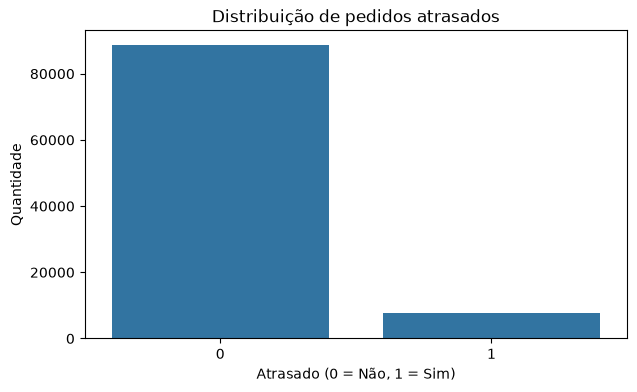

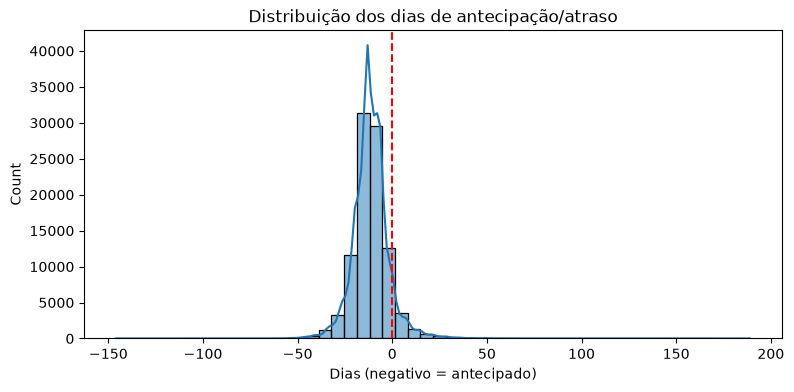

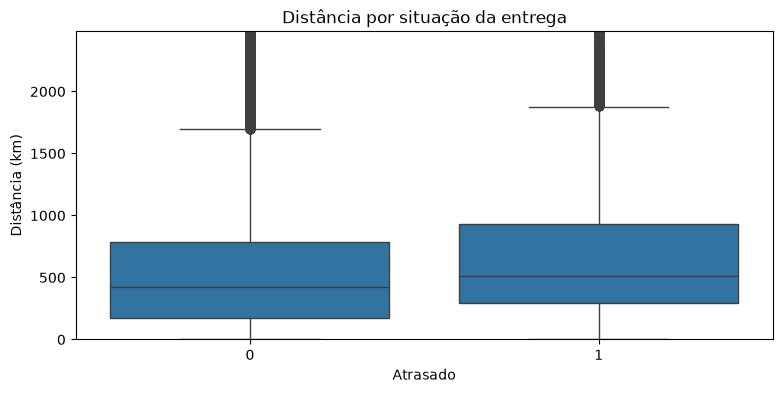

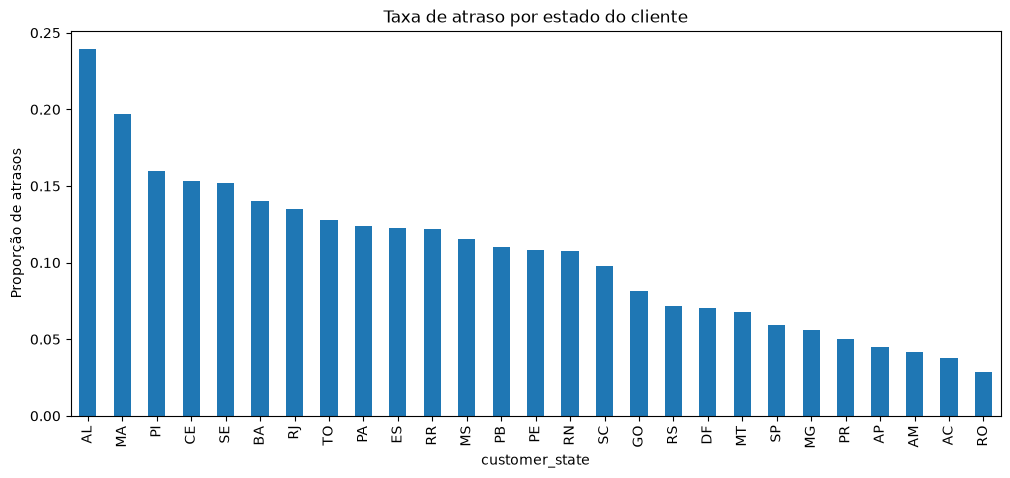

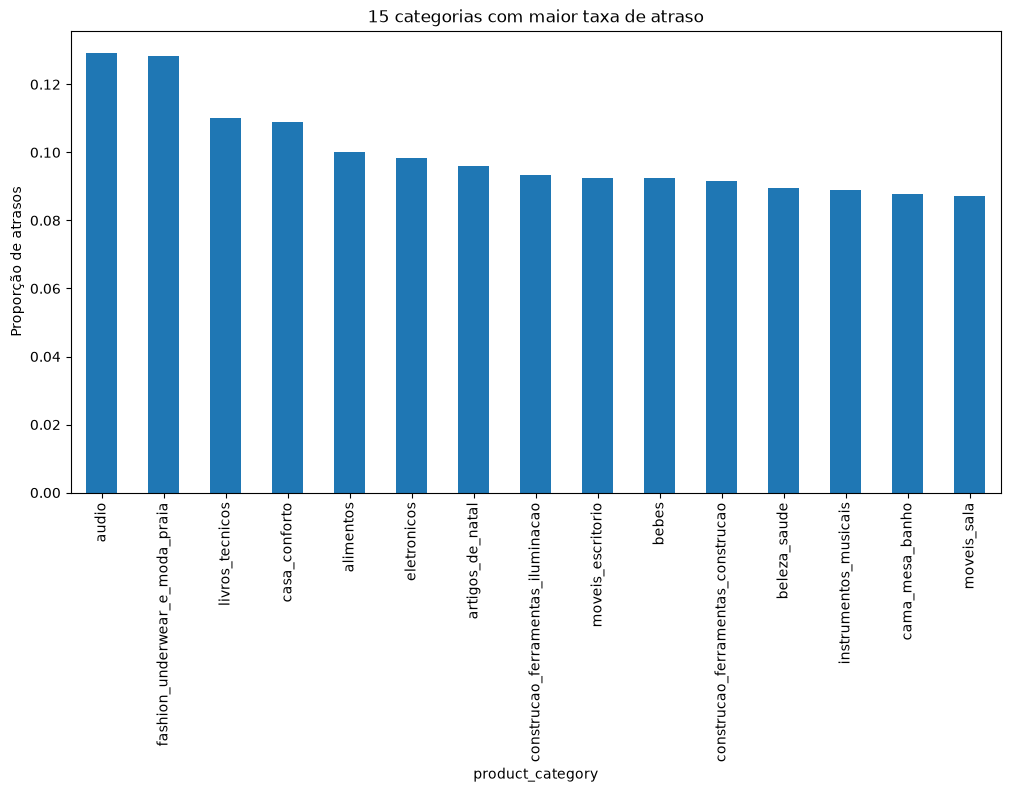

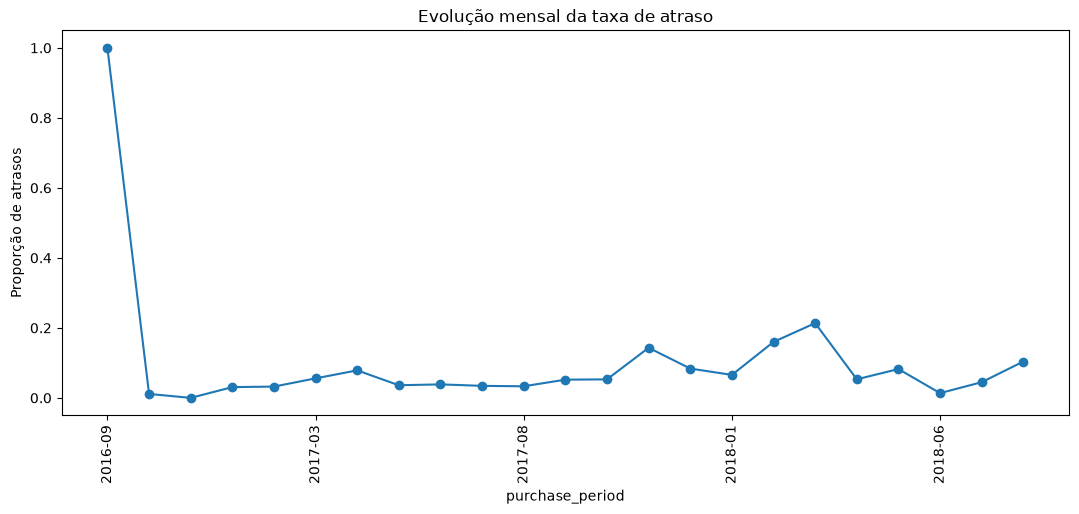

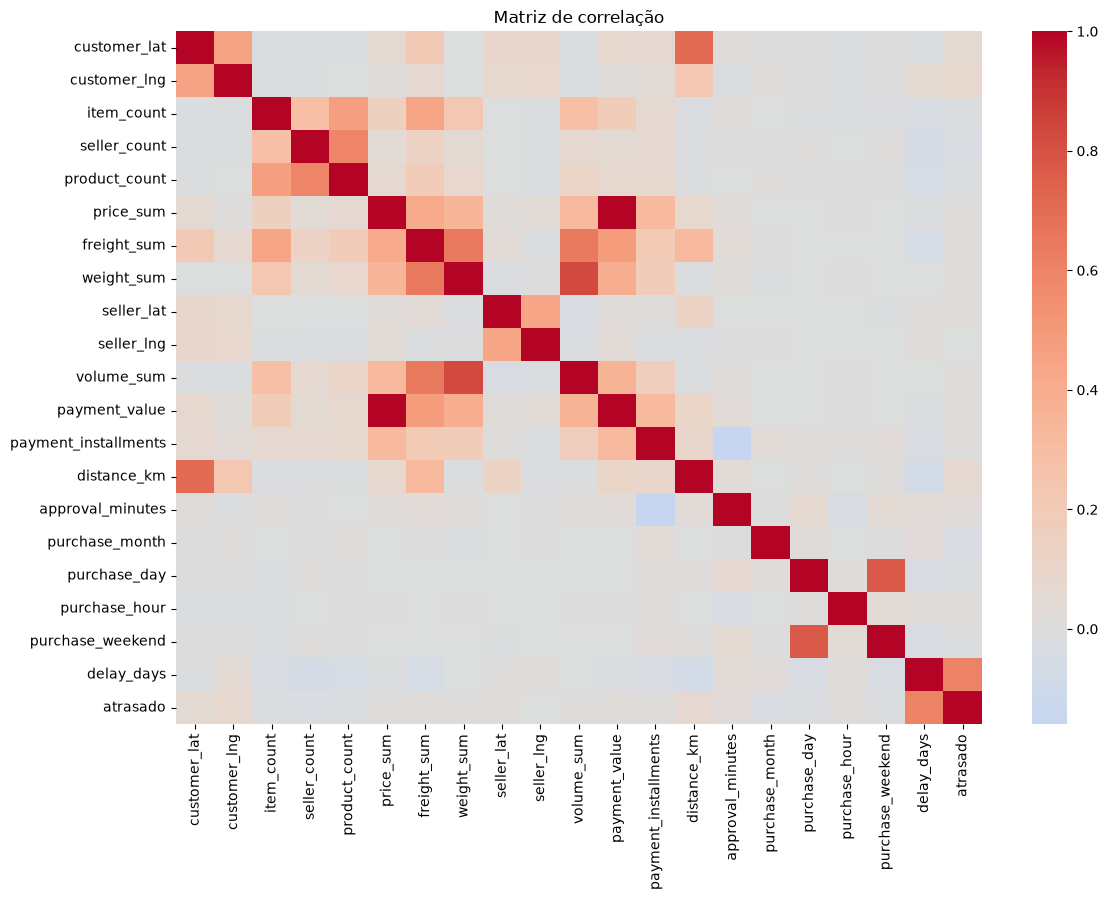

In [71]:

# 1. Informações gerais
print(df.info())

print("\nEstatísticas descritivas:")
print(df.describe())

print("\nValores ausentes:")
print(df.isna().sum().sort_values(ascending=False))

# 2. Distribuição da variável-alvo
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="atrasado")
plt.title("Distribuição de pedidos atrasados")
plt.xlabel("Atrasado (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade")
plt.show()

# 3. Distribuição dos dias de atraso
plt.figure(figsize=(9, 4))
sns.histplot(df["delay_days"], bins=50, kde=True)
plt.axvline(0, linestyle="--", color="red")
plt.title("Distribuição dos dias de antecipação/atraso")
plt.xlabel("Dias (negativo = antecipado)")
plt.show()

# 4. Relação entre distância e atraso
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="atrasado", y="distance_km")
plt.title("Distância por situação da entrega")
plt.xlabel("Atrasado")
plt.ylabel("Distância (km)")
plt.ylim(0, df["distance_km"].quantile(0.99))
plt.show()

# 5. Taxa de atraso por estado do cliente
atrasos_estado = (
    df.groupby("customer_state")["atrasado"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
atrasos_estado.plot(kind="bar")
plt.title("Taxa de atraso por estado do cliente")
plt.ylabel("Proporção de atrasos")
plt.show()

# 6. Taxa de atraso por categoria
atrasos_categoria = (
    df.groupby("product_category")["atrasado"]
    .agg(["mean", "count"])
    .query("count >= 100")
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(12, 6))
atrasos_categoria["mean"].head(15).plot(kind="bar")
plt.title("15 categorias com maior taxa de atraso")
plt.ylabel("Proporção de atrasos")
plt.show()

# 7. Evolução mensal
df["purchase_period"] = (
    df["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

atrasos_mes = df.groupby("purchase_period")["atrasado"].mean()

plt.figure(figsize=(13, 5))
atrasos_mes.plot(marker="o")
plt.title("Evolução mensal da taxa de atraso")
plt.xticks(rotation=90)
plt.ylabel("Proporção de atrasos")
plt.show()

# 8. Correlação entre variáveis numéricas
numericas = df.select_dtypes(include=np.number)

plt.figure(figsize=(13, 9))
sns.heatmap(
    numericas.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Matriz de correlação")
plt.show()


In [72]:

# Variáveis utilizadas
numericas = [
    "item_count", "seller_count", "product_count", "price_sum",
    "freight_sum", "weight_sum", "volume_sum", "payment_value",
    "payment_installments", "approval_minutes", "distance_km",
    "purchase_month", "purchase_day", "purchase_hour", "purchase_weekend"
]

categoricas = [
    "customer_state", "seller_state", "product_category", "payment_type"
]

features = numericas + categoricas

# Remover registros sem variável-alvo e ordenar cronologicamente
df_modelo = df.dropna(subset=["atrasado"]).sort_values(
    "order_purchase_timestamp"
).copy()

X = df_modelo[features]
y = df_modelo["atrasado"]

# Divisão temporal
n = len(df_modelo)

fim_treino = int(n * 0.70)
fim_validacao = int(n * 0.85)

X_treino = X.iloc[:fim_treino]
y_treino = y.iloc[:fim_treino]

X_validacao = X.iloc[fim_treino:fim_validacao]
y_validacao = y.iloc[fim_treino:fim_validacao]

X_teste = X.iloc[fim_validacao:]
y_teste = y.iloc[fim_validacao:]

# Pré-processamento numérico
pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pré-processamento categórico
pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Transformação dos dados
preprocessador = ColumnTransformer([
    ("num", pipeline_numerico, numericas),
    ("cat", pipeline_categorico, categoricas)
])

X_treino = preprocessador.fit_transform(X_treino).astype("float32")
X_validacao = preprocessador.transform(X_validacao).astype("float32")
X_teste = preprocessador.transform(X_teste).astype("float32")

y_treino = y_treino.to_numpy().astype("float32")
y_validacao = y_validacao.to_numpy().astype("float32")
y_teste = y_teste.to_numpy().astype("float32")

# NOVO: Balanceamento por undersampling
from sklearn.utils import resample

dados_treino = pd.DataFrame(X_treino)
dados_treino["target"] = y_treino

classe_0 = dados_treino[dados_treino["target"] == 0]
classe_1 = dados_treino[dados_treino["target"] == 1]

classe_0 = resample(classe_0, replace=False, n_samples=len(classe_1) * 3, random_state=42)

dados_balanceados = pd.concat([classe_0, classe_1]).sample(frac=1, random_state=42)

X_treino_balanceado = dados_balanceados.drop(columns="target").to_numpy()
y_treino_balanceado = dados_balanceados["target"].to_numpy()

print("Distribuição após balanceamento:")
print(pd.Series(y_treino_balanceado).value_counts())

print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)


Distribuição após balanceamento:
0.0    18288
1.0     6096
Name: count, dtype: int64
Treino: (67519, 140)
Validação: (14468, 140)
Teste: (14469, 140)


## Comparação ampliada de modelos para prever atrasos

Este notebook mantém a preparação dos dados e a divisão temporal já existentes e compara:

- Baseline majoritária (referência simples)
- Regressão Logística
- Random Forest
- Gradient Boosting
- HistGradientBoosting
- XGBoost
- LightGBM
- CatBoost
- MLP (rede neural com Keras)

**Referência externa:** um benchmark público do Olist reportou 84,5% de acurácia para Random Forest, mas o Gradient Boosting teve ROC-AUC de 0,810 e PR-AUC de 0,336. A acurácia isolada pode enganar: prever todos os pedidos como "no prazo" já alcança cerca de 91,9% nesse conjunto. Por isso, a comparação principal será pela **PR-AUC**, que é mais informativa para a classe minoritária (atrasos).

Referência dos resultados: https://huggingface.co/samuelalex37/olist-delivery-risk-model

**Importante:** a página pública apresenta métricas, mas não disponibiliza o código-fonte completo do treinamento. Portanto, o Random Forest abaixo é uma implementação de referência adaptada ao seu pipeline, não uma cópia literal do código daquele autor.

Todos os modelos recebem o mesmo treino balanceado por undersampling 2:1. Validação e teste mantêm a distribuição original. O limiar é escolhido na validação; o teste é reservado para a avaliação final do modelo selecionado.

Se algum pacote opcional não estiver instalado, execute em uma célula:
`%pip install xgboost catboost lightgbm`
e reinicie o kernel.


In [73]:
# Imports adicionais
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# XGBoost é opcional
try:
    from xgboost import XGBClassifier
    XGBOOST_DISPONIVEL = True
except ImportError:
    XGBOOST_DISPONIVEL = False
    print("XGBoost não está instalado. Será ignorado.")

# CatBoost é opcional
try:
    from catboost import CatBoostClassifier
    CATBOOST_DISPONIVEL = True
except ImportError:
    CATBOOST_DISPONIVEL = False
    print("CatBoost não está instalado. Será ignorado.")

# LightGBM é opcional
try:
    from lightgbm import LGBMClassifier
    LIGHTGBM_DISPONIVEL = True
except ImportError:
    LIGHTGBM_DISPONIVEL = False
    print("LightGBM não está instalado. Será ignorado.")

# Garantir rótulos inteiros para os modelos
y_treino_balanceado = y_treino_balanceado.astype(int)
y_validacao = y_validacao.astype(int)
y_teste = y_teste.astype(int)

print("Distribuição do treino balanceado:")
print(pd.Series(y_treino_balanceado).value_counts())
print("\\nDistribuição da validação (original):")
print(pd.Series(y_validacao).value_counts())
print("\\nDistribuição do teste (original):")
print(pd.Series(y_teste).value_counts())


Distribuição do treino balanceado:
0    18288
1     6096
Name: count, dtype: int64
\nDistribuição da validação (original):
0    13695
1      773
Name: count, dtype: int64
\nDistribuição do teste (original):
0    13512
1      957
Name: count, dtype: int64


In [74]:
# Função para escolher o limiar usando somente a validação
def escolher_limiar(y_real, probabilidades):
    precisao, recall, thresholds = precision_recall_curve(y_real, probabilidades)

    f1_scores = (
        2 * precisao[:-1] * recall[:-1] /
        (precisao[:-1] + recall[:-1] + 1e-8)
    )

    melhor_indice = np.argmax(f1_scores)
    return float(thresholds[melhor_indice])


# Função para obter métricas de validação
def calcular_metricas(y_real, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    return {
        "limiar": limiar,
        "acertos": int((np.asarray(y_real) == previsoes).sum()),
        "accuracy": accuracy_score(y_real, previsoes),
        "precision": precision_score(y_real, previsoes, zero_division=0),
        "recall": recall_score(y_real, previsoes, zero_division=0),
        "f1": f1_score(y_real, previsoes, zero_division=0),
        "roc_auc": roc_auc_score(y_real, probabilidades),
        "pr_auc": average_precision_score(y_real, probabilidades)
    }


# Dicionários para guardar modelos, históricos e resultados
modelos = {}
historicos = {}
resultados_validacao = {}
probabilidades_validacao = {}


In [75]:
# 1. Baseline: sempre prevê a classe majoritária
modelo_baseline = DummyClassifier(strategy="most_frequent")
modelo_baseline.fit(X_treino_balanceado, y_treino_balanceado)
modelos["Baseline majoritária"] = modelo_baseline


# 2. Regressão Logística
modelo_log = LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42)
modelo_log.fit(X_treino_balanceado, y_treino_balanceado)
modelos["Regressão Logística"] = modelo_log


# 3. Random Forest: modelo de referência com bom desempenho em benchmark público
modelo_rf = RandomForestClassifier(n_estimators=400, max_depth=None, min_samples_split=5, min_samples_leaf=2, max_features="sqrt", random_state=42, n_jobs=-1)
modelo_rf.fit(X_treino_balanceado, y_treino_balanceado)
modelos["Random Forest"] = modelo_rf


# 4. Gradient Boosting
modelo_gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=42)
modelo_gb.fit(X_treino_balanceado, y_treino_balanceado)
modelos["Gradient Boosting"] = modelo_gb


# 5. HistGradientBoosting
modelo_hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=42)
modelo_hgb.fit(X_treino_balanceado, y_treino_balanceado)
modelos["HistGradientBoosting"] = modelo_hgb


# 6. XGBoost (se instalado)
if XGBOOST_DISPONIVEL:
    modelo_xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, objective="binary:logistic", eval_metric="logloss", random_state=42, n_jobs=-1)
    modelo_xgb.fit(X_treino_balanceado, y_treino_balanceado)
    modelos["XGBoost"] = modelo_xgb


# 7. LightGBM (se instalado)
if LIGHTGBM_DISPONIVEL:
    modelo_lgbm = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, max_depth=-1, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=-1)
    modelo_lgbm.fit(X_treino_balanceado, y_treino_balanceado)
    modelos["LightGBM"] = modelo_lgbm


# 8. CatBoost (se instalado)
if CATBOOST_DISPONIVEL:
    modelo_cat = CatBoostClassifier(iterations=500, depth=6, learning_rate=0.05, loss_function="Logloss", eval_metric="PRAUC", random_seed=42, verbose=False, allow_writing_files=False, thread_count=-1)
    modelo_cat.fit(X_treino_balanceado, y_treino_balanceado)
    modelos["CatBoost"] = modelo_cat


print("Modelos tradicionais treinados:", list(modelos.keys()))


Modelos tradicionais treinados: ['Baseline majoritária', 'Regressão Logística', 'Random Forest', 'Gradient Boosting', 'HistGradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost']


In [81]:
# 5. MLP (rede neural com Keras)
modelo_mlp = keras.Sequential([
    layers.Input(shape=(X_treino_balanceado.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

modelo_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=200,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    verbose=1
)

historico_mlp = modelo_mlp.fit(
    X_treino_balanceado,
    y_treino_balanceado,
    validation_data=(X_validacao, y_validacao),
    epochs=150,
    batch_size=200,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

modelos["MLP"] = modelo_mlp
historicos["MLP"] = historico_mlp


Epoch 1/150
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7409 - auc: 0.6095 - loss: 0.5605 - pr_auc: 0.3228 - val_accuracy: 0.9323 - val_auc: 0.6305 - val_loss: 0.5468 - val_pr_auc: 0.0779 - learning_rate: 0.0010
Epoch 2/150
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7486 - auc: 0.6570 - loss: 0.5362 - pr_auc: 0.3725 - val_accuracy: 0.9381 - val_auc: 0.6360 - val_loss: 0.4603 - val_pr_auc: 0.0817 - learning_rate: 0.0010
Epoch 3/150
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7504 - auc: 0.6714 - loss: 0.5291 - pr_auc: 0.3902 - val_accuracy: 0.9345 - val_auc: 0.6398 - val_loss: 0.4006 - val_pr_auc: 0.0846 - learning_rate: 0.0010
Epoch 4/150
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7526 - auc: 0.6830 - loss: 0.5240 - pr_auc: 0.4057 - val_accuracy: 0.9239 - val_auc: 0.6378 - val_loss: 0.3760 - val_pr_auc: 0.0834 - learning_rate: 0.0010
Epoch 5/150
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7537 - auc: 0.6910 - loss: 0.5199 - pr_au

In [82]:
# Avaliação de todos os modelos na validação
for nome, modelo_atual in modelos.items():
    if nome == "MLP":
        prob_val = modelo_atual.predict(X_validacao, verbose=0).ravel()
    else:
        prob_val = modelo_atual.predict_proba(X_validacao)[:, 1]

    limiar_atual = escolher_limiar(y_validacao, prob_val)
    metricas = calcular_metricas(y_validacao, prob_val, limiar_atual)

    resultados_validacao[nome] = metricas
    probabilidades_validacao[nome] = prob_val

# Tabela comparativa
tabela_validacao = pd.DataFrame(resultados_validacao).T
tabela_validacao = tabela_validacao.sort_values("pr_auc", ascending=False)

print("Resultados na validação:")
display(tabela_validacao.round(4))

# Seleção pelo PR-AUC de validação (não pelo conjunto de teste)
melhor_nome = tabela_validacao["pr_auc"].idxmax()
melhor_modelo = modelos[melhor_nome]
melhor_limiar = resultados_validacao[melhor_nome]["limiar"]

print("\nMelhor modelo pela PR-AUC de validação:", melhor_nome)
print("Limiar escolhido na validação:", round(melhor_limiar, 4))


Resultados na validação:


,limiar,acertos,accuracy,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.2841,12071.0,0.8343,0.1144,0.3118,0.1674,0.6379,0.0961
Gradient Boosting,0.2279,12464.0,0.8615,0.1175,0.2445,0.1587,0.6168,0.0921
HistGradientBoosting,0.2952,13227.0,0.9142,0.1609,0.1436,0.1517,0.5989,0.0918
MLP,0.3655,12754.0,0.8815,0.1263,0.2057,0.1565,0.6064,0.0893
Regressão Logística,0.6235,11365.0,0.7855,0.1037,0.3946,0.1643,0.6364,0.0881
LightGBM,0.2098,11847.0,0.8188,0.0908,0.2652,0.1353,0.5996,0.0878
XGBoost,0.1654,10306.0,0.7123,0.0825,0.4334,0.1387,0.5995,0.0873
CatBoost,0.2051,11640.0,0.8045,0.0975,0.3221,0.1497,0.6126,0.0850
Baseline majoritária,0.0000,773.0,0.0534,0.0534,1.0000,0.1014,0.5000,0.0534



Melhor modelo pela PR-AUC de validação: Random Forest
Limiar escolhido na validação: 0.2841


Modelo avaliado: Random Forest
Limiar: 0.2841
Acertos: 12098 de 14469
Acurácia: 0.8361324210380814

Relatório de classificação:
              precision    recall  f1-score   support

    No prazo       0.93      0.89      0.91     13512
    Atrasado       0.07      0.12      0.09       957

    accuracy                           0.84     14469
   macro avg       0.50      0.50      0.50     14469
weighted avg       0.88      0.84      0.86     14469

ROC-AUC: 0.5000879283432722
PR-AUC: 0.06708223866193948
F1: 0.08772604848018468
Recall: 0.11912225705329153
Precisão: 0.06942752740560293


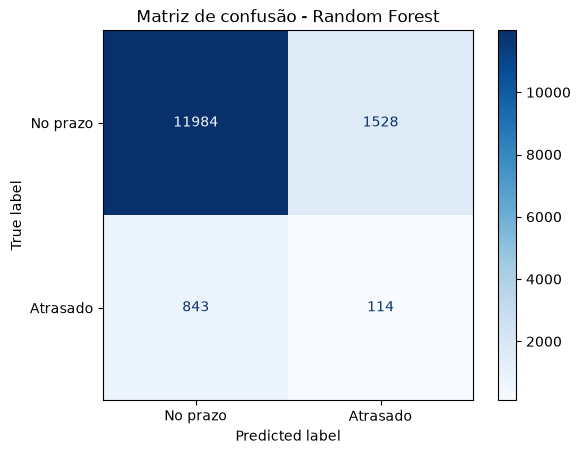

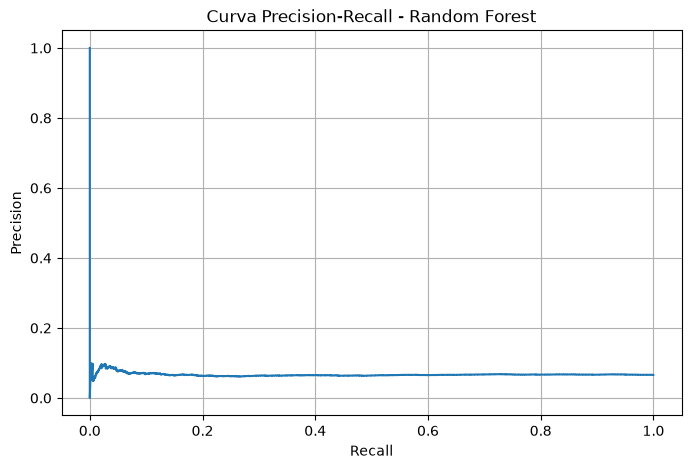

In [78]:
# Avaliação final: somente o melhor modelo no conjunto de teste
if melhor_nome == "MLP":
    probabilidades_teste = melhor_modelo.predict(X_teste, verbose=0).ravel()
else:
    probabilidades_teste = melhor_modelo.predict_proba(X_teste)[:, 1]
# y_teste = y_treino_balanceado.copy()
previsoes_teste = (probabilidades_teste >= melhor_limiar).astype(int)
print("Modelo avaliado:", melhor_nome)
print("Limiar:", round(melhor_limiar, 4))
print("Acertos:", int((y_teste == previsoes_teste).sum()), "de", len(y_teste))
print("Acurácia:", accuracy_score(y_teste, previsoes_teste))
print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes_teste,
    target_names=["No prazo", "Atrasado"],
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_teste, probabilidades_teste))
print("PR-AUC:", average_precision_score(y_teste, probabilidades_teste))
print("F1:", f1_score(y_teste, previsoes_teste, zero_division=0))
print("Recall:", recall_score(y_teste, previsoes_teste, zero_division=0))
print("Precisão:", precision_score(y_teste, previsoes_teste, zero_division=0))

# Matriz de confusão
cm = confusion_matrix(y_teste, previsoes_teste)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No prazo", "Atrasado"]
).plot(cmap="Blues")

plt.title(f"Matriz de confusão - {melhor_nome}")
plt.show()

# Curva Precision-Recall
precision, recall, _ = precision_recall_curve(y_teste, probabilidades_teste)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.title(f"Curva Precision-Recall - {melhor_nome}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid()
plt.show()


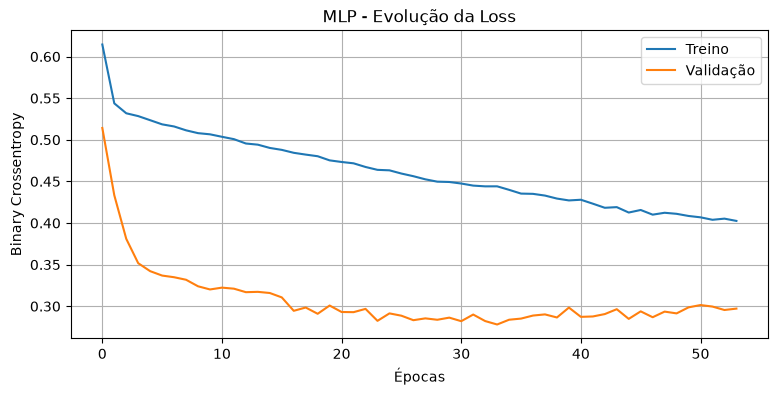

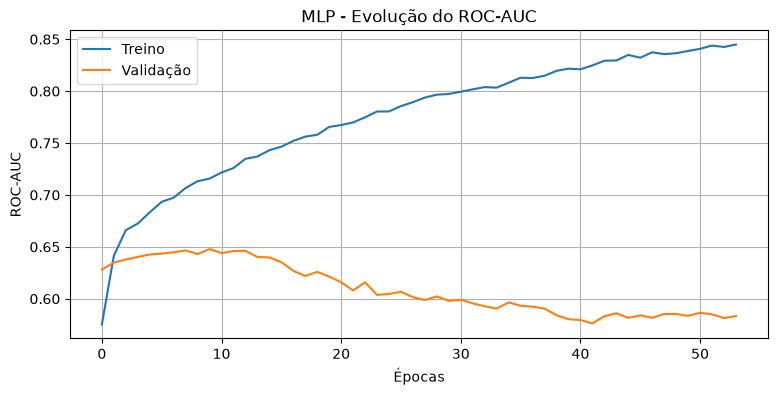

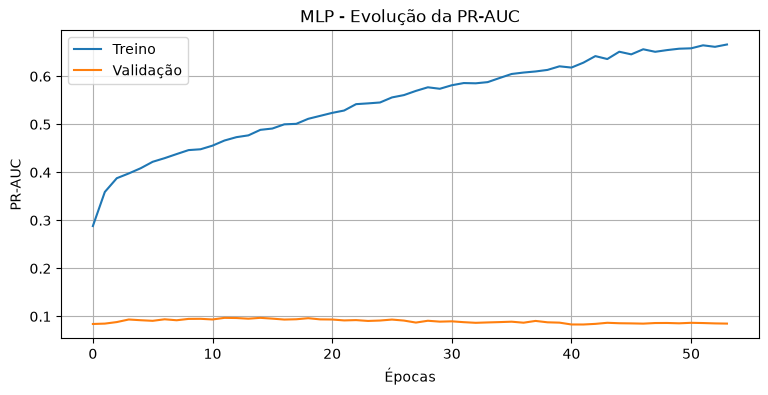

In [79]:
# Gráficos de treinamento da MLP
historico = historicos["MLP"]

plt.figure(figsize=(9, 4))
plt.plot(historico.history["loss"], label="Treino")
plt.plot(historico.history["val_loss"], label="Validação")
plt.title("MLP - Evolução da Loss")
plt.xlabel("Épocas")
plt.ylabel("Binary Crossentropy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(historico.history["auc"], label="Treino")
plt.plot(historico.history["val_auc"], label="Validação")
plt.title("MLP - Evolução do ROC-AUC")
plt.xlabel("Épocas")
plt.ylabel("ROC-AUC")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(historico.history["pr_auc"], label="Treino")
plt.plot(historico.history["val_pr_auc"], label="Validação")
plt.title("MLP - Evolução da PR-AUC")
plt.xlabel("Épocas")
plt.ylabel("PR-AUC")
plt.legend()
plt.grid()
plt.show()


In [80]:
# Salvar o melhor modelo, o pré-processador e o limiar escolhido
joblib.dump(preprocessador, "preprocessador_olist.joblib")

if melhor_nome == "MLP":
    melhor_modelo.save("melhor_modelo_olist.keras")
else:
    joblib.dump(melhor_modelo, "melhor_modelo_olist.joblib")

with open("limiar_olist.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write(str(melhor_limiar))

print("Modelo, pré-processador e limiar salvos.")


Modelo, pré-processador e limiar salvos.
